#### In this notebook i will use the lsm.py to see what happens to a gaussian input and the symbol that is recovvered

In [168]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

# print(sys.executable)

In [169]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 

from nonlinear.lsm import LSM
from nonlinear.solvers import KdV, Whitham
from linear.help import *


In [170]:
N = 2**8
P = 20
x = np.linspace(-P/2, P/2, N, endpoint=False)
g = np.exp(-x**2)



In [171]:
# plt.plot(x, g);

In [172]:
# kdv1 = KdV(P = P, dt = 5e-3, T = 5, u0 = g, save_every=1)
kdv1 = Whitham(P = P, dt = 1e-3, T = 1, u0 = g, save_every=1)
t,u = kdv1.splitStep()

In [173]:
# animate_solution_nb(x, u)

In [174]:
lsm = LSM([u], kdv1.dt)
lsm_X = lsm.lsm()



In [175]:
half = N//2
idx = N//2
idx_p = N//2 + idx
idx_n = N//2 - idx + 1
ell , n = lsm.fit_symbol(k = kdv1.k, idx_range = [idx_n, idx_p], deg = 5)

In [176]:
fit_table(ell, n, part="imag")

,ξ^5,ξ^4,ξ^3,ξ^2,ξ^1,ξ^0
ell,-8.913167e-08,1.556479e-19,0.000236,-2.898982e-16,-0.318405,2.823961e-14
n,-6.488707e-10,1.244665e-20,0.000001,4.444427e-17,-0.500152,2.080865e-15


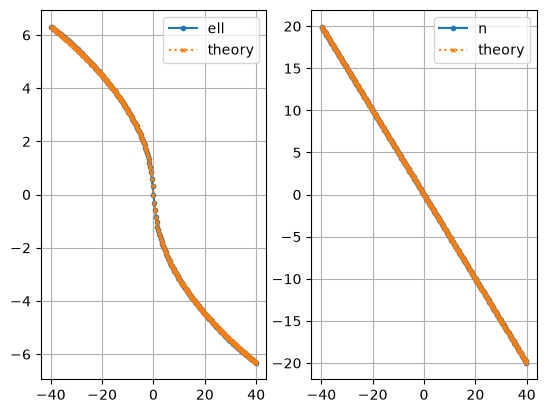

In [177]:
# lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: -np.sign(k)*np.sqrt(k*np.tanh(k)), n_t = lambda k: -0.5*k)
